In [26]:
# Task: Table Booking and Online Delivery

# Determine the percentage of restaurants that offer table booking and online delivery.
# Compare the average ratings of restaurants with table booking and those without.
# Analyze the availability of online delivery among restaurants with different price ranges.

In [27]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

# Load dataset 
data = pd.read_csv("/home/vansh-kumar/cognifyz Task/Dataset .csv")
# data

print("\nDataset Shape:", data.shape)


Dataset Shape: (9551, 21)


In [28]:
# check required columns

required_columns = ["Has Table booking",
                    "Has Online delivery",
                    "Aggregate rating"]

missing_columns = [col for col in required_columns if col not in data.columns]

if missing_columns:
    raise ValueError(f"Missing columns: {missing_columns}\n"
                     f"Available columns: {data.columns.tolist()}")
    
def normalize_yes_no(series):
    values = series.astype("string").str.strip().str.lower()
    return values.map({"yes": "Yes", "no": "No"})

data["Table booking"] = normalize_yes_no(data["Has Table booking"])

data["Has Online Delivery"] = normalize_yes_no(data["Has Online delivery"])

data["Aggregate rating"] = pd.to_numeric(data["Aggregate rating"], errors="coerce")

# calculate table booking statistics

def service_summary(column, service_name):
    counts = data[column].value_counts().reindex(["Yes", "No"],fill_value=0)
    known_count = counts.sum()
    
    print("\nRestaturant counts:")
    print(counts.to_string())
    
    if known_count:
        percentages = counts/known_count*100
        print("\nPercentage among known response:")
        print(percentages.round(2).to_string())
        
        print(f"\nOffering {service_name}:"
              f"{percentages.get('Yes', 0):.2f}%")
    print("Missing response:", data[column].isna().sum())
    return counts

table_counts = service_summary("Table booking", "table booking")
delivery_counts = service_summary("Has Online Delivery", "online delivery")

              


Restaturant counts:
Table booking
Yes    1158
No     8393

Percentage among known response:
Table booking
Yes    12.12
No     87.88

Offering table booking:12.12%
Missing response: 0

Restaturant counts:
Has Online Delivery
Yes    2451
No     7100

Percentage among known response:
Has Online Delivery
Yes    25.66
No     74.34

Offering online delivery:25.66%
Missing response: 0


In [33]:
# compare rating by service availability

def rating_comparison(column, service_name):
    comparison = data.groupby(column)["Aggregate rating"].agg(
        Restaurant_Count="count",
        Average_Rating="mean",
        Median_Rating="median",
        Standard_Deviation="std"
    ).reindex(["Yes", "No"])

    print(f"\n{service_name} and restaurant ratings:")
    print(comparison.round(3).to_string())

    return comparison


table_rating = rating_comparison("Table booking", "Table booking")
delivery_rating = rating_comparison("Has Online Delivery", "Online delivery")


Table booking and restaurant ratings:
               Restaurant_Count  Average_Rating  Median_Rating  Standard_Deviation
Table booking                                                                     
Yes                        1158           3.442            3.6               0.881
No                         8393           2.559            3.1               1.554

Online delivery and restaurant ratings:
                     Restaurant_Count  Average_Rating  Median_Rating  Standard_Deviation
Has Online Delivery                                                                     
Yes                              2451           3.249            3.4               0.844
No                               7100           2.465            3.1               1.640


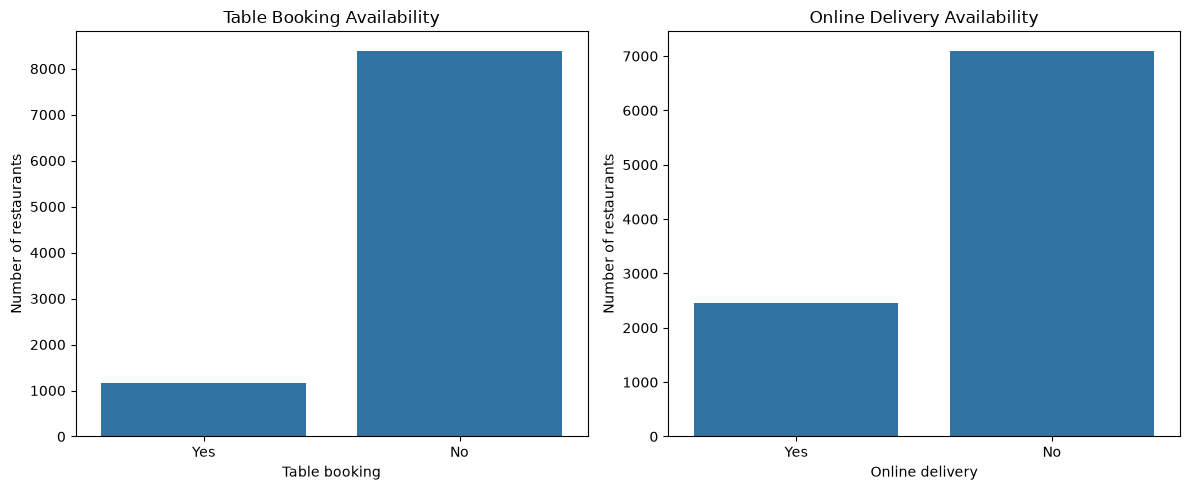

In [42]:
# visualize service availability

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

sns.barplot(
    x=table_counts.index,
    y=table_counts.values,
    ax=axes[0]
)
axes[0].set_title("Table Booking Availability")
axes[0].set_xlabel("Table booking")
axes[0].set_ylabel("Number of restaurants")

sns.barplot(
    x=delivery_counts.index,
    y=delivery_counts.values,
    ax=axes[1]
)
axes[1].set_title("Online Delivery Availability")
axes[1].set_xlabel("Online delivery")
axes[1].set_ylabel("Number of restaurants")

plt.tight_layout()

plt.show()


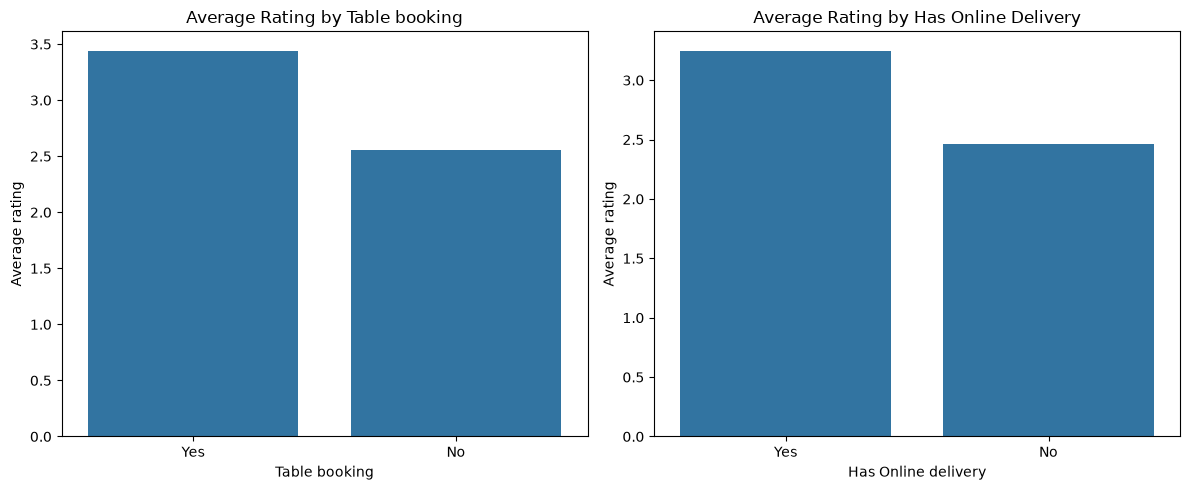

In [40]:
# visualize average rating

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

sns.barplot(
    data=data[data["Table booking"].notna()],
    x="Table booking",
    y="Aggregate rating",
    order=["Yes", "No"],
    estimator="mean",
    errorbar=None,
    ax=axes[0]
)
axes[0].set_title("Average Rating by Table booking")
axes[0].set_xlabel("Table booking")
axes[0].set_ylabel("Average rating")

sns.barplot(
    data=data[data["Has Online delivery"].notna()],
    x="Has Online Delivery",
    y="Aggregate rating",
    order=["Yes", "No"],
    estimator="mean",
    errorbar=None,
    ax=axes[1]
)
axes[1].set_title("Average Rating by Has Online Delivery")
axes[1].set_xlabel("Has Online delivery")
axes[1].set_ylabel("Average rating")

plt.tight_layout()
plt.show()

In [41]:
for name, comparison in [
    ("Table booking", table_rating),
    ("Online delivery", delivery_rating)
]:
    available = comparison.loc["Yes", "Average_Rating"]
    unavailable = comparison.loc["No", "Average_Rating"]

    if pd.notna(available) and pd.notna(unavailable):
        difference = available - unavailable

        print(
            f"\n{name}: difference in average rating "
            f"(Yes - No) = {difference:.3f}"
        )

        if difference > 0:
            print("Restaurants offering the service have a higher average rating.")
        elif difference < 0:
            print("Restaurants not offering the service have a higher average rating.")
        else:
            print("Both groups have equal average ratings.")

print("\nAnalysis completed successfully!")



Table booking: difference in average rating (Yes - No) = 0.883
Restaurants offering the service have a higher average rating.

Online delivery: difference in average rating (Yes - No) = 0.784
Restaurants offering the service have a higher average rating.

Analysis completed successfully!
